# Practical No.7

### perform following operations
1. Import all the required Python Libraries. 
2. Locate open source data 
3. Provide a clear description of the data and its source  
4. Load the Dataset into the pandas data frame. 
5. Display the initial statistics.  
6. Scan all variables for missing values and inconsistencies.If there are missing values and/or inconsistencies, use any of the suitable techniques to deal with them. 
7. Scan all numeric variables for outliers. If there are outliers, use any of the suitable techniques to deal with them.
8. Apply data transformations on at least one of the variables.  
9. Turn categorical variables into quantitative variables in Python. 

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [21]:
df = pd.read_csv("DATASET/Iris.csv")

In [22]:
df.columns

Index(['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='object')

In [23]:
df.shape

(150, 6)

In [24]:
# statistical analysis
df.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


In [25]:
# categorical statistics
print(df.describe(include='object'))

            Species
count           150
unique            3
top     Iris-setosa
freq             50


In [26]:
print(df.isnull().sum())

Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64


In [ ]:
# this dataset not contain any null values 
# but if have 
# Fill missing values (Median for numbers, Mode for text)
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = df[col].fillna(df[col].mode()[0])
    else:
        df[col] = df[col].fillna(df[col].median()

In [27]:
# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())
#df.drop_duplicates(inplace=True)


Duplicate Records: 0


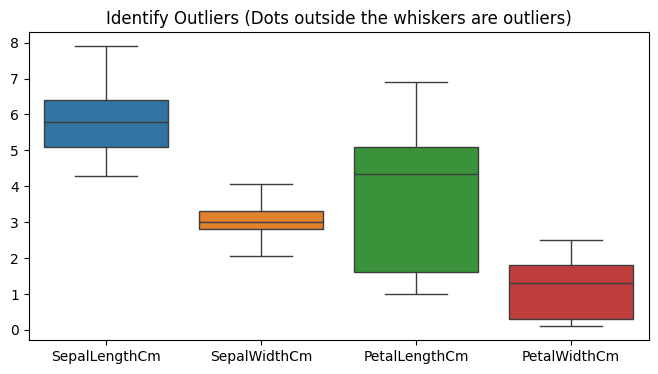

In [35]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df[numeric_cols])
plt.title("Identify Outliers (Dots outside the whiskers are outliers)")
plt.show()

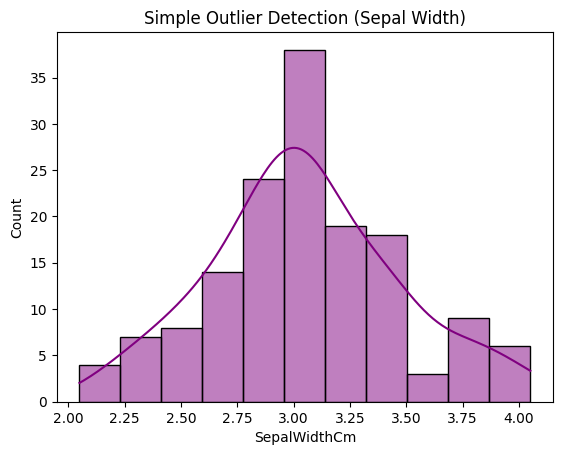

In [36]:
sns.histplot(df['SepalWidthCm'], kde=True, color="purple")

plt.title("Outlier Detection (Sepal Width)")
plt.show()

In [29]:
# Handle Outliers (Capping with IQR Method)
numeric_cols = ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']
for col in numeric_cols:
    Q1, Q3 = df[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    df[col] = df[col].clip(lower=Q1 - 1.5 * IQR, upper=Q3 + 1.5 * IQR)

In [30]:
# Data Transformation
df['PetalLength_Log'] = np.log1p(df['PetalLengthCm'])

In [32]:
# perform encoding
from sklearn.preprocessing import OneHotEncoder
en = OneHotEncoder(sparse_output=False ,dtype ='int')
en_species = en.fit_transform(df[['Species']])


In [33]:
# Convert encoded features into a DataFrame and combine
en_df = pd.DataFrame(en_species, columns=en.get_feature_names_out(['Species']))
df = pd.concat([df.reset_index(drop=True), en_df], axis=1).drop(columns=['Species'])

In [34]:
print(df.head())

   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm  \
0   1            5.1           3.5            1.4           0.2   
1   2            4.9           3.0            1.4           0.2   
2   3            4.7           3.2            1.3           0.2   
3   4            4.6           3.1            1.5           0.2   
4   5            5.0           3.6            1.4           0.2   

   PetalLength_Log  Species_Iris-setosa  Species_Iris-versicolor  \
0         0.875469                    1                        0   
1         0.875469                    1                        0   
2         0.832909                    1                        0   
3         0.916291                    1                        0   
4         0.875469                    1                        0   

   Species_Iris-virginica  
0                       0  
1                       0  
2                       0  
3                       0  
4                       0  


# Practical No.8

### Implement feature extraction (PCA from sctrach) on real world dataset

In [76]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [77]:
df = pd.read_csv("DATASET/Iris.csv")

In [78]:
print(df.head())

   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa


In [80]:
X = df.iloc[:, :-1].values # : means all rows ,:-1 all col except last one
y = df.iloc[:, -1].values # all rows of last cloumn

In [82]:
print("Original Shape:", X.shape)

Original Shape: (150, 5)


In [85]:
# Standardization
mean = np.mean(X, axis=0)
std = np.std(X, axis=0, ddof=1)

Z = (X - mean) / std
print(Z)

[[-1.71479731e+00 -8.97673879e-01  1.02861128e+00 -1.33679402e+00
  -1.30859282e+00]
 [-1.69177989e+00 -1.13920048e+00 -1.24540379e-01 -1.33679402e+00
  -1.30859282e+00]
 [-1.66876248e+00 -1.38072709e+00  3.36720285e-01 -1.39346985e+00
  -1.30859282e+00]
 [-1.64574507e+00 -1.50149039e+00  1.06089953e-01 -1.28011819e+00
  -1.30859282e+00]
 [-1.62272765e+00 -1.01843718e+00  1.25924161e+00 -1.33679402e+00
  -1.30859282e+00]
 [-1.59971024e+00 -5.35383973e-01  1.95113261e+00 -1.16676652e+00
  -1.04652483e+00]
 [-1.57669283e+00 -1.50149039e+00  7.97980949e-01 -1.33679402e+00
  -1.17755883e+00]
 [-1.55367541e+00 -1.01843718e+00  7.97980949e-01 -1.28011819e+00
  -1.30859282e+00]
 [-1.53065800e+00 -1.74301699e+00 -3.55170711e-01 -1.33679402e+00
  -1.30859282e+00]
 [-1.50764058e+00 -1.13920048e+00  1.06089953e-01 -1.28011819e+00
  -1.43962681e+00]
 [-1.48462317e+00 -5.35383973e-01  1.48987194e+00 -1.28011819e+00
  -1.30859282e+00]
 [-1.46160576e+00 -1.25996379e+00  7.97980949e-01 -1.22344235e+00

In [86]:
# Calculate covariance matrix
cov_matrix = np.cov(Z, rowvar=False)

print("\nCovariance Matrix:")
print(cov_matrix)


Covariance Matrix:
[[ 1.          0.71667627 -0.39772881  0.88274732  0.89975858]
 [ 0.71667627  1.         -0.10936925  0.87175416  0.81795363]
 [-0.39772881 -0.10936925  1.         -0.4205161  -0.35654409]
 [ 0.88274732  0.87175416 -0.4205161   1.          0.9627571 ]
 [ 0.89975858  0.81795363 -0.35654409  0.9627571   1.        ]]


In [87]:
# Calculate eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

print("\nEigenvalues:")
print(eigenvalues)

print("\nEigenvectors:")
print(eigenvectors)


Eigenvalues:
[0.02060107 0.08823837 0.23413122 0.92176284 3.7352665 ]

Eigenvectors:
[[-0.0067323   0.55978662 -0.67406853 -0.02275157 -0.48136016]
 [ 0.26061932  0.40999945  0.64520569  0.38285827 -0.44844975]
 [-0.12416613 -0.09491665 -0.27427786  0.92007839  0.23195044]
 [-0.79848404 -0.28817343  0.13238322  0.03074857 -0.51079205]
 [ 0.52824072 -0.65305918 -0.19127876  0.07356757 -0.5024696 ]]


In [88]:
# Sort eigenvalues in descending order
sorted_indices = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[sorted_indices]
eigenvectors = eigenvectors[:, sorted_indices]

In [89]:
# Select top 2 principal components
W = eigenvectors[:, :2]

print("\nSelected Principal Components:")
print(W)



Selected Principal Components:
[[-0.48136016 -0.02275157]
 [-0.44844975  0.38285827]
 [ 0.23195044  0.92007839]
 [-0.51079205  0.03074857]
 [-0.5024696   0.07356757]]


In [90]:
# Transform original data into 2D
X_pca = np.dot(Z, W)

print("Reduced Dataset:")
print(X_pca[:5])

print("Reduced Shape:", X_pca.shape)


Reduced Dataset:
[[ 2.80693543  0.50436099]
 [ 2.63669428 -0.64962308]
 [ 2.86986634 -0.31996395]
 [ 2.801549   -0.57543545]
 [ 2.87026785  0.66822901]]
Reduced Shape: (150, 2)


In [91]:
# Calculate explained variance
explained_variance = eigenvalues / np.sum(eigenvalues)

print("Explained Variance Ratio:",explained_variance)
print("Variance captured by 2 components:",np.sum(explained_variance[:2]) * 100, "%")

Explained Variance Ratio: [0.7470533  0.18435257 0.04682624 0.01764767 0.00412021]
Variance captured by 2 components: 93.14058689070457 %


In [92]:
# 11. Create reduced dataset
pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2']
)

pca_df['Species'] = y

print("\nFinal PCA Dataset:")
print(pca_df.head())


Final PCA Dataset:
        PC1       PC2      Species
0  2.806935  0.504361  Iris-setosa
1  2.636694 -0.649623  Iris-setosa
2  2.869866 -0.319964  Iris-setosa
3  2.801549 -0.575435  Iris-setosa
4  2.870268  0.668229  Iris-setosa


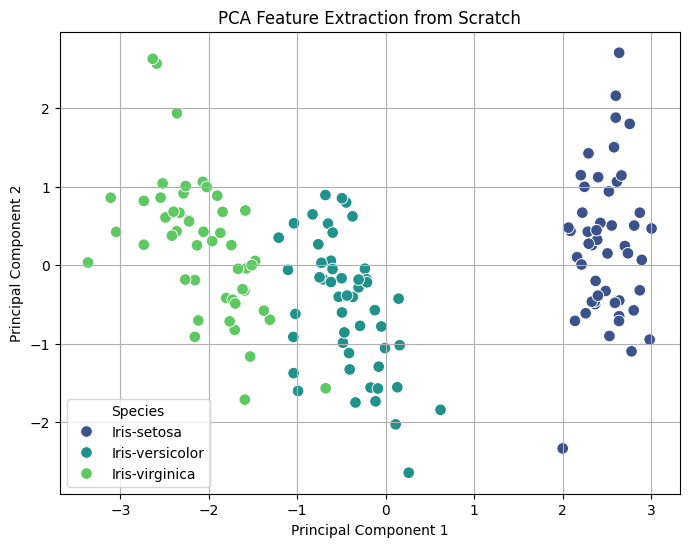

In [93]:
# Visualize PCA results
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Species',
    palette='viridis',
    s=70
)

plt.title("PCA Feature Extraction from Scratch")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Species")
plt.grid(True)
plt.show()

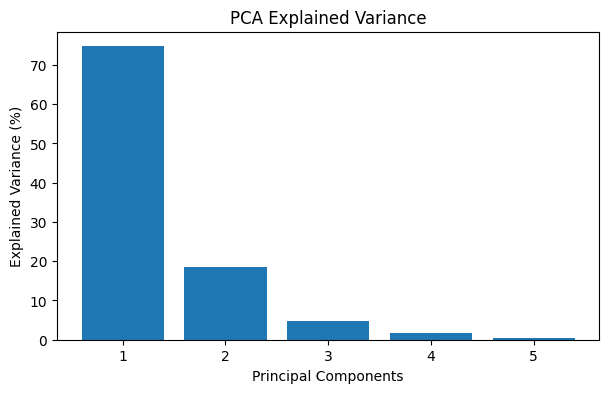

In [94]:
# Explained variance graph
plt.figure(figsize=(7, 4))

plt.bar(
    range(1, len(explained_variance) + 1),
    explained_variance * 100
)

plt.xlabel("Principal Components")
plt.ylabel("Explained Variance (%)")
plt.title("PCA Explained Variance")
plt.xticks(range(1, len(explained_variance) + 1))
plt.show()

# Practicle No.9A

### create a linear regression model using python

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd 
import seaborn as sns

In [2]:
# load the dataset
df = pd.read_csv("DATASET/multiple_linear_regression_dataset.csv")

In [3]:
df

,age,experience,income
0,25,1,30450
1,30,3,35670
2,47,2,31580
3,32,5,40130
4,43,10,47830
5,51,7,41630
6,28,5,41340
7,33,4,37650
8,37,5,40250
9,39,8,45150


In [4]:
df.describe()

,age,experience,income
count,20.000000,20.000000,20.000000
mean,39.650000,6.200000,40735.500000
std,10.027725,4.124382,8439.797625
min,23.000000,1.000000,27840.000000
25%,31.500000,3.750000,35452.500000
50%,40.000000,5.000000,40190.000000
75%,47.000000,9.000000,45390.000000
max,58.000000,17.000000,63600.000000


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   age         20 non-null     int64
 1   experience  20 non-null     int64
 2   income      20 non-null     int64
dtypes: int64(3)
memory usage: 608.0 bytes


In [6]:
# check the null values 
df.isnull().sum()

age           0
experience    0
income        0
dtype: int64

In [7]:
# corelation between columns 
df.corr()

,age,experience,income
age,1.000000,0.615165,0.532204
experience,0.615165,1.000000,0.984227
income,0.532204,0.984227,1.000000


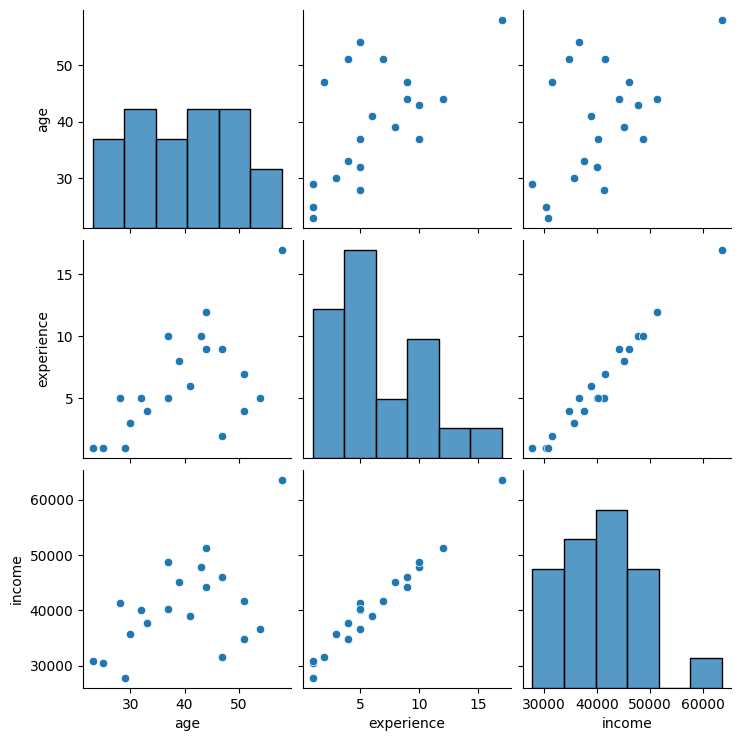

In [11]:
# plot a pairplot 
sns.pairplot(df)

In [8]:
# set dependent and independent variable
X = df[['age','experience']]
y = df['income']

In [12]:
# split the dataset
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [13]:
X_train

,age,experience
8,37,5
5,51,7
11,47,9
3,32,5
18,44,9
16,58,17
13,51,4
2,47,2
9,39,8
19,37,10


In [20]:
from sklearn.preprocessing import StandardScaler
sc =StandardScaler()
X_train =sc.fit_transform(X_train)
X_test =sc.transform(X_test)

In [21]:
# logic for model 
# we have two columns age and experience we have to predict income 

In [22]:
from sklearn.linear_model import LinearRegression
model  = LinearRegression()
model.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [23]:
print(model.intercept_)
print(model.coef_)

42426.25
[-884.53894609 8465.28543013]


In [24]:
# make a prediction on test data 
y_pred = model.predict(X_test)
y_pred

array([31093.38107376, 31295.49954076, 40250.46080162, 34897.6958918 ])

In [25]:
from sklearn.metrics import mean_absolute_error,r2_score,root_mean_squared_error,mean_squared_error

print("MAE :", mean_absolute_error(y_test, y_pred))
print("MSE :", mean_squared_error(y_test, y_pred))
print("RMSE:", root_mean_squared_error(y_test, y_pred))
print("R²  :", r2_score(y_test, y_pred))

MAE : 797.9113810821891
MSE : 753796.7693734562
RMSE: 868.2147023481325
R²  : 0.9387098237077885


In [26]:
# calculate the residual and plot distplot
residule  = y_test,y_pred
residule

(0     30450
 17    30870
 15    38900
 1     35670
 Name: income, dtype: int64,
 array([31093.38107376, 31295.49954076, 40250.46080162, 34897.6958918 ]))

/tmp/ipykernel_21500/2242492933.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(residule)


<Axes: ylabel='Density'>

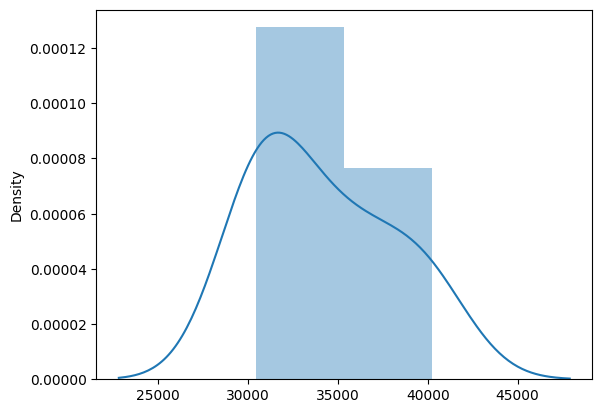

In [29]:
sns.distplot(residule)

# Practical No.9B

### create a logestic regression model using python

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("DATASET/Social_Network_Ads.csv")


In [3]:
df.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Age              400 non-null    int64
 1   EstimatedSalary  400 non-null    int64
 2   Purchased        400 non-null    int64
dtypes: int64(3)
memory usage: 9.5 KB


In [6]:
X = df[['Age', 'EstimatedSalary']]
y = df['Purchased']

In [7]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=0
)


In [8]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()

X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [9]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()
model.fit(X_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [10]:
y_pred = model.predict(X_test)
y_pred

array([0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1])

In [11]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.89


In [12]:
con_matrix = confusion_matrix(y_test,y_pred)
print("\nConfusion Matrix:\n", con_matrix)


Confusion Matrix:
 [[65  3]
 [ 8 24]]


In [13]:
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))


Classification Report:

              precision    recall  f1-score   support

           0       0.89      0.96      0.92        68
           1       0.89      0.75      0.81        32

    accuracy                           0.89       100
   macro avg       0.89      0.85      0.87       100
weighted avg       0.89      0.89      0.89       100



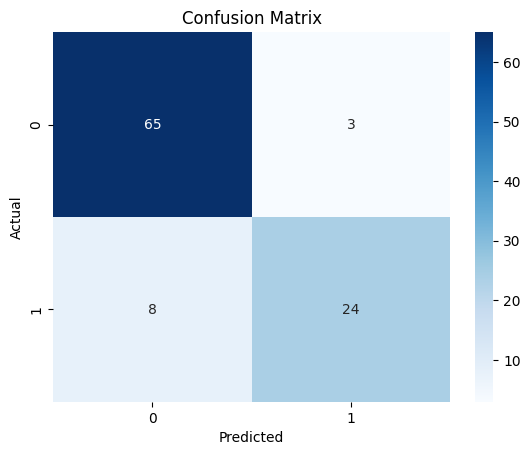

In [15]:
sns.heatmap(con_matrix, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
age = int(input("Enter customer age: "))
salary = float(input("Enter estimated salary: "))


# make a new prediction 
new_customer =pd.DataFrame(
    [[age,salary]],
    columns =['Age','EstimatedSalary']
)

# apply transformation (jo training mai tha)
new_customer_sc = sc.transform(new_customer)

# predict
pred = model.predict(new_customer_sc)

# Predict probability
probability = model.predict_proba(new_customer_sc)

if pred[0] == 1:
    print("Customer will Purchase the Product")
else:
    print("Customer will NOT Purchase the Product")

print("Purchase Probability:", probability[0][1] * 100, "%")

# Practical No.10[A]

### build email spam classifier using Support vector Machine(SVM)

In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [55]:
df = pd.read_excel("DATASET/email spam dataset.xlsx")
df

,label,txt,call,free,claim,mobile,u,can,get,love,home
0,ham,0,0,0,0,0,0,0,0,0,0
1,spam,0,1,2,0,2,1,0,0,0,0
2,ham,0,0,0,0,0,0,0,0,0,0
3,spam,1,0,0,0,0,0,0,0,0,0
4,ham,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
1109,ham,0,0,0,0,0,1,0,0,0,0
1110,ham,0,0,0,0,0,0,0,0,0,0
1111,ham,0,0,0,0,0,0,0,0,0,0
1112,ham,0,0,0,0,0,0,0,0,1,0


In [56]:
# Explore dataset
print(df.head())
print(df.shape)
print(df.info())

  label  txt  call  free  claim  mobile  u  can  get  love  home
0   ham    0     0     0      0       0  0    0    0     0     0
1  spam    0     1     2      0       2  1    0    0     0     0
2   ham    0     0     0      0       0  0    0    0     0     0
3  spam    1     0     0      0       0  0    0    0     0     0
4   ham    0     0     0      0       0  0    0    0     0     0
(1114, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1114 entries, 0 to 1113
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   label   1114 non-null   object
 1   txt     1114 non-null   int64 
 2   call    1114 non-null   int64 
 3   free    1114 non-null   int64 
 4   claim   1114 non-null   int64 
 5   mobile  1114 non-null   int64 
 6   u       1114 non-null   int64 
 7   can     1114 non-null   int64 
 8   get     1114 non-null   int64 
 9   love    1114 non-null   int64 
 10  home    1114 non-null   int64 
dtypes: int64(10), objec

In [57]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate records:")
print(df.duplicated().sum())

Missing values:
label     0
txt       0
call      0
free      0
claim     0
mobile    0
u         0
can       0
get       0
love      0
home      0
dtype: int64

Duplicate records:
1009


In [58]:
df = df.dropna()
df = df.drop_duplicates()

df = df.reset_index(drop=True)

print("Final Dataset Shape:", df.shape)

Final Dataset Shape: (105, 11)


In [59]:
X = df.drop('label', axis=1)

y = df['label']

print("Input Shape:", X.shape)
print("Output Shape:", y.shape)

Input Shape: (105, 10)
Output Shape: (105,)


In [52]:
# Convert email text into numerical features
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=5000
)

X = tfidf.fit_transform(X)

In [60]:
print("X shape:", X.shape)
print("y shape:", y.shape)

print("X samples:", len(X))
print("y samples:", len(y))

X shape: (105, 10)
y shape: (105,)
X samples: 105
y samples: 105


In [61]:
y = y.map({
    'ham': 0,
    'spam': 1
})

print(y.head())

0    0
1    1
2    1
3    1
4    0
Name: label, dtype: int64


In [62]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (78, 10)
Testing Data: (27, 10)


In [63]:
from sklearn.svm import LinearSVC
model = LinearSVC(
    C=1.0,
    random_state=42,
    max_iter=10000
)

In [65]:
model.fit(X_train, y_train)
print("SVM Model Trained Successfully")

SVM Model Trained Successfully


In [67]:
y_pred = model.predict(X_test)
y_pred

array([1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0,
       0, 0, 0, 1, 0])

In [69]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.7777777777777778


In [70]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score
)

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[13  1]
 [ 5  8]]


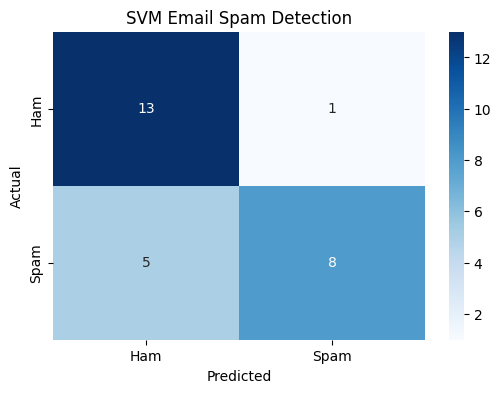

In [71]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM Email Spam Detection")

plt.show()

In [72]:
TN, FP, FN, TP = cm.ravel()

print("True Negative:", TN)
print("False Positive:", FP)
print("False Negative:", FN)
print("True Positive:", TP)

True Negative: 13
False Positive: 1
False Negative: 5
True Positive: 8


In [73]:
precision = precision_score(y_test, y_pred)

recall = recall_score(y_test, y_pred)

print("Precision:", precision)
print("Recall:", recall)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Ham', 'Spam']
))

Precision: 0.8888888888888888
Recall: 0.6153846153846154

Classification Report:
              precision    recall  f1-score   support

         Ham       0.72      0.93      0.81        14
        Spam       0.89      0.62      0.73        13

    accuracy                           0.78        27
   macro avg       0.81      0.77      0.77        27
weighted avg       0.80      0.78      0.77        27



In [75]:
new_email = pd.DataFrame(
    [[0, 2, 1, 1, 1, 0, 1, 1, 0, 0]],
    columns=X.columns
)

prediction = model.predict(new_email)

if prediction[0] == 1:
    print("email is SPAM")
else:
    print("email is NORMAL (HAM)")

email is SPAM


# Practical No.10[B]

### Implement the KNN on Iris dataset

In [95]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [96]:
df = pd.read_csv("DATASET/Iris.csv")

In [97]:
print(df.head())

   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa


In [98]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB
None


In [99]:
df = df.drop(columns=["Id"], errors="ignore")

In [100]:
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

In [101]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [102]:
# feature Scaling 
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [104]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [106]:
# prediction
y_pred = knn.predict(X_test)
y_pred

array(['Iris-setosa', 'Iris-virginica', 'Iris-versicolor',
       'Iris-versicolor', 'Iris-setosa', 'Iris-versicolor', 'Iris-setosa',
       'Iris-setosa', 'Iris-virginica', 'Iris-versicolor',
       'Iris-virginica', 'Iris-virginica', 'Iris-virginica',
       'Iris-versicolor', 'Iris-setosa', 'Iris-setosa', 'Iris-setosa',
       'Iris-versicolor', 'Iris-versicolor', 'Iris-versicolor',
       'Iris-setosa', 'Iris-virginica', 'Iris-versicolor',
       'Iris-versicolor', 'Iris-virginica', 'Iris-versicolor',
       'Iris-versicolor', 'Iris-setosa', 'Iris-virginica', 'Iris-setosa'],
      dtype=object)

In [108]:
from sklearn.metrics import confusion_matrix,accuracy_score,precision_score,recall_score,classification_report
cm = confusion_matrix(y_test, y_pred)
cm

array([[10,  0,  0],
       [ 0, 10,  0],
       [ 0,  2,  8]])

In [110]:
accuracy = accuracy_score(y_test, y_pred)
accuracy

0.9333333333333333

In [111]:
precision = precision_score(y_test, y_pred, average='macro', zero_division=0)
recall = recall_score(y_test, y_pred, average='macro', zero_division=0)

In [112]:
print(precision)
print(recall)

0.9444444444444445
0.9333333333333332


In [113]:
# Calculate TP, FP, TN, FN for each class
print("\nTP, FP, TN, FN for each class:")

for i, class_name in enumerate(knn.classes_):
    TP = cm[i, i]
    FP = cm[:, i].sum() - TP
    FN = cm[i, :].sum() - TP
    TN = cm.sum() - (TP + FP + FN)

    print("\nClass:", class_name)
    print("TP:", TP)
    print("FP:", FP)
    print("TN:", TN)
    print("FN:", FN)


TP, FP, TN, FN for each class:

Class: Iris-setosa
TP: 10
FP: 0
TN: 20
FN: 0

Class: Iris-versicolor
TP: 10
FP: 2
TN: 18
FN: 0

Class: Iris-virginica
TP: 8
FP: 0
TN: 20
FN: 2


In [114]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.83      1.00      0.91        10
 Iris-virginica       1.00      0.80      0.89        10

       accuracy                           0.93        30
      macro avg       0.94      0.93      0.93        30
   weighted avg       0.94      0.93      0.93        30



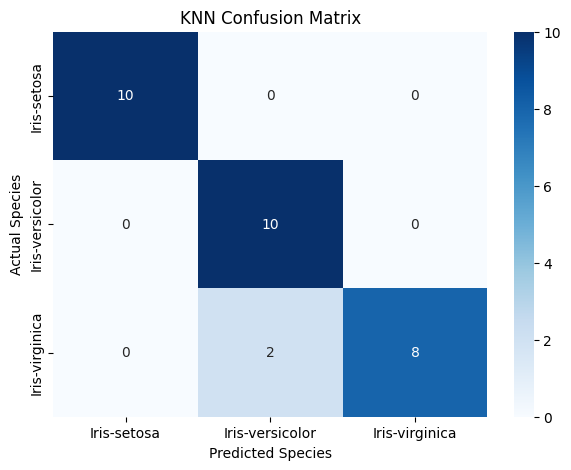

In [115]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=knn.classes_,
    yticklabels=knn.classes_
)

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.show()

# Practical No.11

### Implement Kmeans clustering and determine no. clusters using elbow method

In [117]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [118]:
df = pd.read_csv("DATASET/sales_data_sample.csv", encoding="latin1")

In [119]:
print(df.head())

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

In [121]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   object 
 6   STATUS            2823 non-null   object 
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   object 
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   object 
 13  CUSTOMERNAME      2823 non-null   object 
 14  PHONE             2823 non-null   object 
 15  ADDRESSLINE1      2823 non-null   object 
 16  ADDRESSLINE2      302 non-null    object 


In [122]:
df.shape

(2823, 25)

In [123]:
# numerical feature 
X = df[['QUANTITYORDERED', 'PRICEEACH', 'SALES']]

In [124]:
X = X.fillna(X.median())

In [127]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [128]:
# apply elbow method 
from sklearn.cluster import KMeans

wcss = []

for i in range(1, 11):
    kmeans = KMeans(
        n_clusters=i,
        init='k-means++',
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

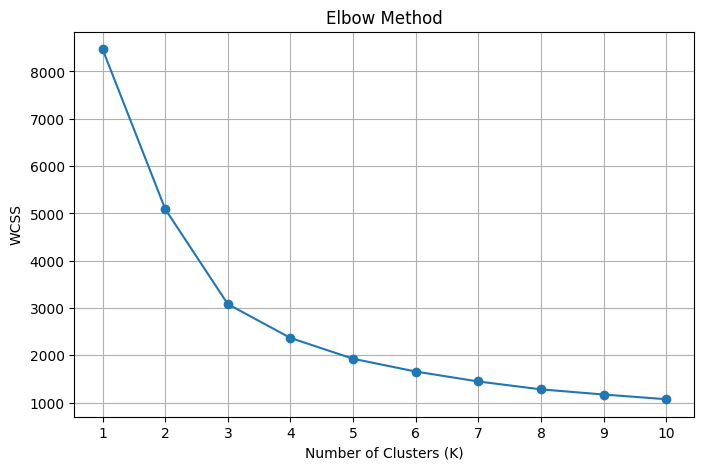

In [129]:
# Plot Elbow Graph
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [130]:
# Select optimal K after observing elbow graph
optimal_k = 4

In [131]:
# Apply K-Means clustering
kmeans = KMeans(
    n_clusters=optimal_k,
    init='k-means++',
    random_state=42,
    n_init=10
)

In [132]:
df['Cluster'] = kmeans.fit_predict(X_scaled)

In [133]:
print("\nCluster Assignments:")
print(df[['QUANTITYORDERED', 'PRICEEACH',
          'SALES', 'Cluster']].head(10))


Cluster Assignments:
   QUANTITYORDERED  PRICEEACH    SALES  Cluster
0               30      95.70  2871.00        2
1               34      81.35  2765.90        2
2               41      94.74  3884.34        1
3               45      83.26  3746.70        0
4               49     100.00  5205.27        1
5               36      96.66  3479.76        2
6               29      86.13  2497.77        2
7               48     100.00  5512.32        1
8               22      98.57  2168.54        2
9               41     100.00  4708.44        1


In [134]:
print("\nNumber of records in each cluster:")
print(df['Cluster'].value_counts().sort_index())


Number of records in each cluster:
Cluster
0    519
1    751
2    989
3    564
Name: count, dtype: int64


In [135]:
# Cluster-wise analysis
print("Cluster Analysis:")
print(df.groupby('Cluster')[
    ['QUANTITYORDERED', 'PRICEEACH', 'SALES']
].mean())

Cluster Analysis:
         QUANTITYORDERED  PRICEEACH        SALES
Cluster                                         
0              43.897881  65.782813  2874.671407
1              43.793609  99.121212  5940.226631
2              27.779575  96.487391  3219.571355
3              28.228723  57.022571  1587.603050


In [136]:
# apply PCA
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

df['PCA1'] = X_pca[:, 0]
df['PCA2'] = X_pca[:, 1]

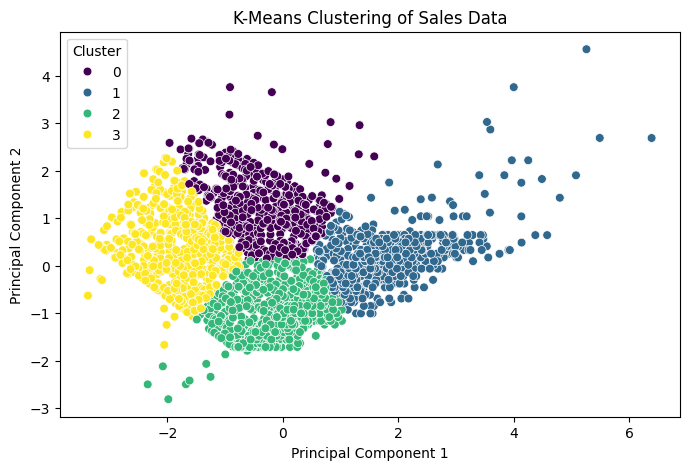

In [137]:
# 14. Visualize clusters
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='PCA1',
    y='PCA2',
    hue='Cluster',
    palette='viridis',
    s=40
)

plt.title("K-Means Clustering of Sales Data")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

In [138]:
print("\nOptimal Number of Clusters:", optimal_k)
print("Final WCSS:", kmeans.inertia_)
print("Clustering Completed")


Optimal Number of Clusters: 4
Final WCSS: 2367.9957025964013
Clustering Completed
